# Fig. 5H, I: Enrichment of events not attributable to genuine infection in the FN fraction

Plot host-range and taxonomic-assignability summaries using Virus–Host DB annotations.
Run `Fig5H_taxonkit.sh` first.


In [1]:

import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

In [2]:
# Define paths
basedir = "/path/to/project"
directory_out = "Fig5HI"

# Output directory
path_out = f"{basedir}/output/revise_final/{directory_out}"

# Input files
path_in = f"{basedir}/output/revise_final/Fig5/"
# Sample metadata
sradata_path = f"{basedir}/data/Infection_Prediction_Stacking_0_sample_list_TN1000.txt"
# Viral metadata
meta_in = f"{path_in}virus_all_4474.meta.txt"
# Virus–Host DB
hostdb_path = f"{basedir}/../../db/virushostdb_260821/virushostdb.tsv"
# Virus taxonomy
virustaxid = f"{path_out}/virus_taxonomy.tsv"
# Host taxonomy
hosttaxid = f"{path_out}/host_taxonomy.tsv"

if not os.path.exists(path_out):
    os.makedirs(path_out)
print("saving files:", path_out)


saving files: /Users/coco/iLab/itolab_backup/backup-latest/Lab/projects/2507blastx/output/revise_final/Fig5HI


# Read metadata

In [3]:
# Read sample metadata
sampledf = pd.read_table(sradata_path)
print("sample info table size:", sampledf.shape)

# Read viral metadata
df = pd.read_table(meta_in, dtype={"Project_Id": "Int64"}, index_col=0).drop("query_seq", axis=1)
print("metadata original size:", df.shape)
# Exclude BLASTn hits to non-viral sequences
df_blastn = df.loc[~(df["is_virus_blastn"]==0), :].copy()
print("metadata size after removed blastn other hits:", df_blastn.shape)

sample info table size: (4474, 10)
metadata original size: (14353, 79)
metadata size after removed blastn other hits: (14036, 79)


# Read Virus–Host DB

In [4]:
# Read Virus–Host DB
hostdb = pd.read_table(hostdb_path)

print("shape of hostdb:", hostdb.shape)
print(
    "NaN in tax id:",
    hostdb["virus tax id"].isna().sum(),
    hostdb["host tax id"].isna().sum()
)

virus_tax = pd.read_table(virustaxid)
host_tax = pd.read_table(hosttaxid)

# Add virus taxonomy
hostdb = hostdb.merge(
    virus_tax,
    left_on="virus tax id",
    right_on="virus_taxid",
    how="left"
)

# Add host taxonomy
hostdb = hostdb.merge(
    host_tax,
    left_on="host tax id",
    right_on="host_taxid",
    how="left"
)

print("shape after merge:", hostdb.shape)

display(hostdb.head(3))
display(hostdb["host_class"].value_counts())

shape of hostdb: (42704, 14)
NaN in tax id: 0 72
shape after merge: (42704, 30)


,virus tax id,virus name,virus lineage,refseq id,KEGG GENOME,KEGG DISEASE,DISEASE,host tax id,host name,host lineage,pmid,evidence,sample type,source organism,virus_taxid,virus_domain,virus_phylum,virus_class,virus_order,virus_family,virus_genus,virus_species,host_taxid,host_domain,host_phylum,host_class,host_order,host_family,host_genus,host_species
0,1482734,aalivirus A1,Viruses; Riboviria; Orthornavirae; Pisuviricot...,NC_023985,NaN,NaN,NaN,8839.0,Anas platyrhynchos,cellular organisms; Eukaryota; Opisthokonta; M...,24659102,"Literature, RefSeq",NaN,NaN,1482734,unclassified Viruses domain,Pisuviricota,Pisoniviricetes,Picornavirales,Picornaviridae,Aalivirus,Aalivirus apekidu,8839.0,Eukaryota,Chordata,Aves,Anseriformes,Anatidae,Anas,Anas platyrhynchos
1,3158377,abaca bunchy top virus,Viruses; Floreoviria; Shotokuvirae; Cressdnavi...,"NC_010314, NC_010315, NC_010316, NC_010317, NC...",NaN,NaN,NaN,214697.0,Musa acuminata AAA Group,cellular organisms; Eukaryota; Viridiplantae; ...,17978886,Literature,NaN,NaN,3158377,unclassified Viruses domain,Cressdnaviricota,Arfiviricetes,Mulpavirales,Nanoviridae,Babuvirus,Babuvirus abacae,214697.0,Eukaryota,Streptophyta,Magnoliopsida,Zingiberales,Musaceae,Musa,Musa acuminata
2,3416944,abalone herpesvirus,Viruses; Duplodnaviria; Heunggongvirae; Peplov...,JX453331,NaN,NaN,NaN,36100.0,Haliotis rubra,cellular organisms; Eukaryota; Opisthokonta; M...,21062506,"Literature, RefSeq",NaN,NaN,3416944,unclassified Viruses domain,Peploviricota,Herviviricetes,Herpesvirales,Malacoherpesviridae,Aurivirus,Aurivirus haliotidmalaco1,36100.0,Eukaryota,Mollusca,Gastropoda,Lepetellida,Haliotidae,Haliotis,Haliotis rubra


host_class
Gammaproteobacteria        12276
Mammalia                    5916
Actinomycetes               5451
Magnoliopsida               4168
unclassified root class     3903
                           ...  
Candidatus Poseidoniia         1
Hydrogenophilia                1
Resentoviricetes               1
Pyramimonadophyceae            1
Aquificia                      1
Name: count, Length: 149, dtype: int64

# Fig. 5H: Composition of samples by the host range of the detected viruses

In [5]:
# Prepare genus-level host information
db = hostdb[["virus_genus", "host_class"]].dropna().copy()
print("hostdb original size", db.shape)
print("#NaN:", db.isna().sum().sum())

host_is_unknown = db["host_class"].str.match(r"(?i)^(unclassified|unknown|$)")
db = db.loc[~host_is_unknown]
print("hostdb filtered size", db.shape)
# Classify genera by whether known hosts include birds or mammals
genus_status = {}

for genus, records in db.groupby("virus_genus"):
    if records["host_class"].isin(["Aves", "Mammalia"]).any():
        genus_status[genus] = "match"
    else:
        genus_status[genus] = "mismatch"


# Classify samples by viral host range
def classify_sample(statuses):
    if (statuses == "match").any():
        return "Other"

    if (statuses == "mismatch").all():
        return "Host mismatch only"

    if (statuses == "unknown").all():
        return "Host unknown only"

    return "Host unknown + host mismatch"


# Set category colors
category_colors = {
    "Host mismatch only": "#ec301bd5",
    "Host unknown + host mismatch": "#ffcd60e7",
    "Host unknown only": "#a9a9a9",
    "Other": "#eeace8ca",
    "BLASTx hit negative": "#e7e7e7",
}
cm_order = ["TP", "FN", "TN", "FP"]

plt.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": "Arial",
})


def plot_sample_host_range():
    contigs = df_blastn[["ID", "genus"]].copy()

    # Treat genera absent from the database as unknown
    contigs["host_status"] = contigs["genus"].map(genus_status)
    contigs["host_status"] = contigs["host_status"].fillna("unknown")

    mode = "unknown"
    is_unclassified = (
        contigs["genus"].str.lower().str.startswith("unclassified", na=False)
    )
    contigs.loc[is_unclassified, "host_status"] = "unknown"

    # Classify samples by viral host range
    sample_categories = (
        contigs.groupby("ID")["host_status"].apply(classify_sample)
    )

    # Include samples without BLASTx viral hits
    samples = sampledf[["ID", "CM"]].copy()
    samples["category"] = samples["ID"].map(sample_categories)
    samples["category"] = samples["category"].fillna("BLASTx hit negative")

    # Calculate category counts and proportions
    counts = pd.crosstab(samples["CM"], samples["category"])
    counts = counts.reindex(
        index=cm_order, columns=list(category_colors), fill_value=0
    )

    total = counts.sum(axis=1)
    percent = counts.div(total.replace(0, np.nan), axis=0) * 100
    percent = percent.fillna(0)

    # Plot
    fig, ax = plt.subplots(figsize=(6, 5), dpi=300)

    percent.plot.bar(
        stacked=True,
        color=list(category_colors.values()),
        width=0.55,
        ax=ax,
    )

    ax.set_title(
        f"Virus genus × Aves/Mammalia\nUnclassified = {mode}",
        fontsize=15,
    )
    ax.set_ylabel("% of samples", fontsize=14)
    ax.set_xlabel("")
    ax.set_xticklabels(
        [f"{group}\n(n={total[group]})" for group in cm_order],
        rotation=0,
        fontsize=13,
    )
    ax.tick_params(axis="y", labelsize=12)
    ax.legend(title="", fontsize=8, loc="upper right")

    # Label segments representing at least 3%
    for container in ax.containers:
        labels = [
            f"{value:.1f}%" if value >= 3 else ""
            for value in container.datavalues
        ]
        ax.bar_label(
            container, labels=labels,
            label_type="center", fontsize=11,
        )

    fig.tight_layout()
    fig.savefig(
        f"{path_out}/genus_Aves_Mammalia_sample_{mode}.pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    return {"samples": samples, "counts": counts, "percent": percent}

hostdb original size (42059, 2)
#NaN: 0
hostdb filtered size (37949, 2)


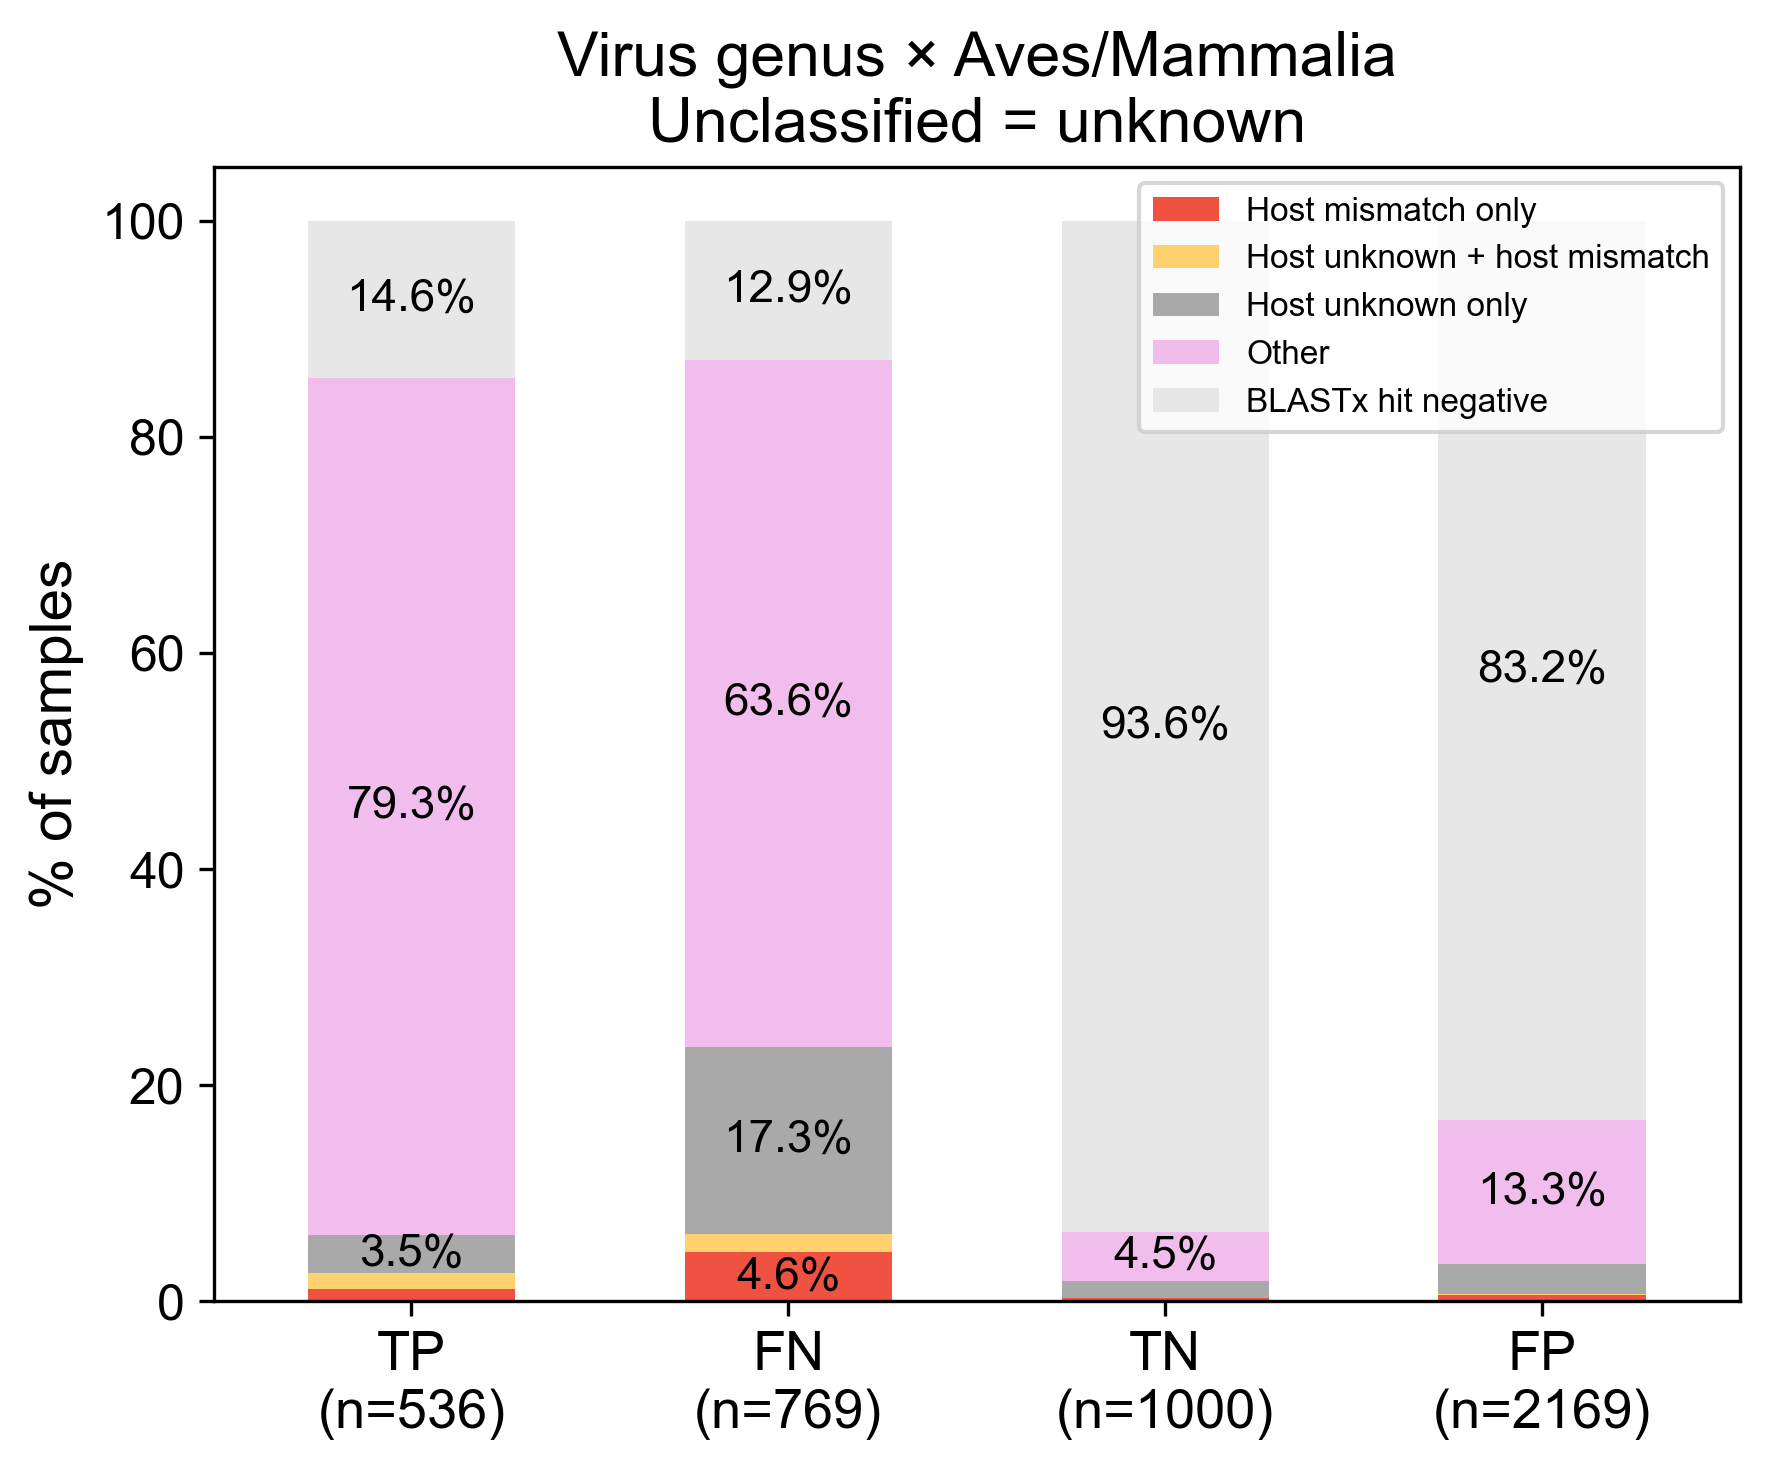

In [6]:
result_unknown = plot_sample_host_range()


In [7]:
# Set output column order
columns = [
    "BLASTx hit negative",
    "Host mismatch only",
    "Host unknown + host mismatch",
    "Host unknown only",
    "Other",
]

# Select categories for the combined proportion
mismatch_columns = [
    "Host mismatch only",
    "Host unknown + host mismatch",
    "Host unknown only",
]

for mode, result in [("unknown", result_unknown)]:
    table = result["percent"].reindex(
        index=["TP", "FN", "TN", "FP"],
        columns=columns,
    ).copy()

    # Sum the selected category percentages
    table["host_mismatch_unknown_sum"] = table[mismatch_columns].sum(axis=1)

    # Calculate the fold change relative to TP
    tp_sum = table.loc["TP", "host_mismatch_unknown_sum"]

    if tp_sum == 0:
        table["fold"] = np.nan  # Undefined if the TP proportion is zero
    else:
        table["fold"] = table["host_mismatch_unknown_sum"] / tp_sum

    # Save proportions
    output_file = (
        f"{path_out}/genus_Aves_Mammalia_sample_{mode}_proportion_with_sum.tsv"
    )
    table.to_csv(
        output_file,
        sep="\t",
        index_label="cm",
        float_format="%.1f",
        na_rep="NA",
    )

    print("Saved:", output_file)
    display(table)

Saved: /Users/coco/iLab/itolab_backup/backup-latest/Lab/projects/2507blastx/output/revise_final/Fig5HI/genus_Aves_Mammalia_sample_unknown_proportion_with_sum.tsv


category,BLASTx hit negative,Host mismatch only,Host unknown + host mismatch,Host unknown only,Other,host_mismatch_unknown_sum,fold
CM,,,,,,,
TP,14.552239,1.119403,1.492537,3.544776,79.291045,6.156716,1.000000
FN,12.873862,4.551365,1.690507,17.295189,63.589077,23.537061,3.822989
TN,93.600000,0.300000,0.000000,1.600000,4.500000,1.900000,0.308606
FP,83.218073,0.599355,0.092208,2.766252,13.324112,3.457815,0.561633


# Fig. 5I: Composition of samples by the taxonomic assignability of the detected viruses

In [8]:
# Identify placeholder names of the form unclassified xxx genus
contigs = df_blastn[["ID", "cm", "genus"]].copy()

contigs["is_unclassified"] = (
    contigs["genus"].str.strip().str.fullmatch(
        r"unclassified\s+.+\s+genus",
        case=False,
        na=False,
    )
)

cm_order = ["TP", "FN", "TN", "FP"]

plt.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": "Arial",
})


# Plot category proportions
def plot_unclassified_genus(counts, category_colors, level):
    counts = counts.reindex(
        index=cm_order,
        columns=list(category_colors),
        fill_value=0,
    )

    total = counts.sum(axis=1)
    percent = counts.div(total.replace(0, np.nan), axis=0) * 100
    percent = percent.fillna(0)

    fig, ax = plt.subplots(figsize=(6, 5), dpi=300)

    percent.plot.bar(
        stacked=True,
        color=list(category_colors.values()),
        width=0.55,
        ax=ax,
    )

    ax.set_title(f"Unclassified virus genus\n{level.capitalize()} level", fontsize=15)
    ax.set_ylabel(f"% of {level}s", fontsize=14)
    ax.set_xlabel("")
    ax.set_xticklabels(
        [f"{group}\n(n={total[group]})" for group in cm_order],
        rotation=0,
        fontsize=13,
    )
    ax.tick_params(axis="y", labelsize=12)
    ax.legend(title="", fontsize=8, loc="upper right")

    for container in ax.containers:
        labels = [
            f"{value:.1f}%" if value >= 3 else ""
            for value in container.datavalues
        ]
        ax.bar_label(
            container, labels=labels,
            label_type="center", fontsize=11,
        )

    fig.tight_layout()
    fig.savefig(
        f"{path_out}/unclassified_genus_{level}_proportion.pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    percent.to_csv(
        f"{path_out}/unclassified_genus_{level}_proportion.tsv",
        sep="\t", index_label="cm", float_format="%.1f",
    )

    return counts, percent

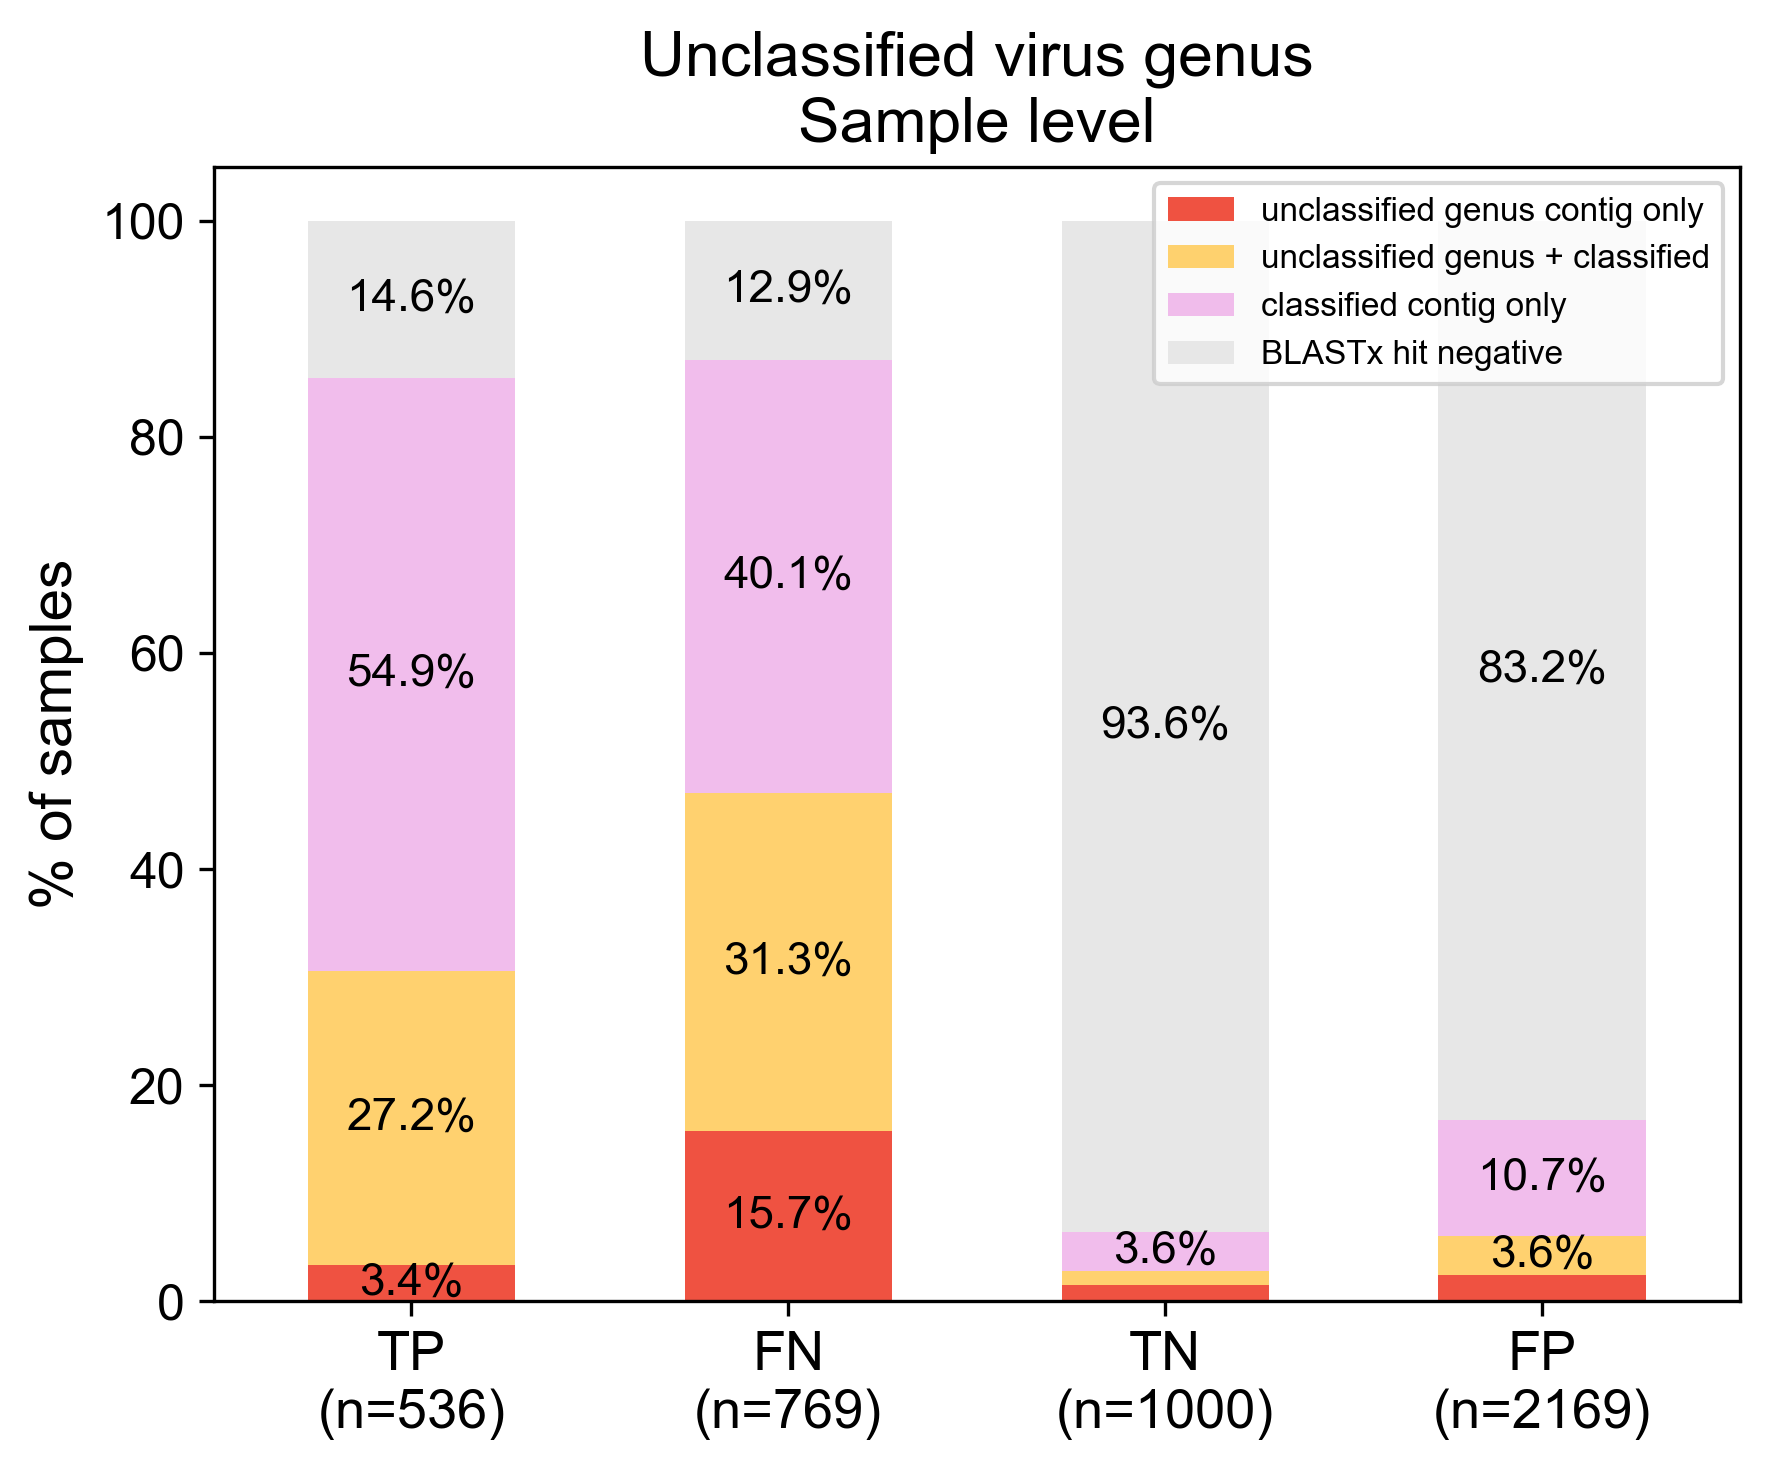

In [9]:
# Classify samples by their contig composition
def classify_unclassified_sample(flags):
    if flags.all():
        return "unclassified genus contig only"

    if flags.any():
        return "unclassified genus + classified"

    return "classified contig only"


sample_categories = (
    contigs.groupby("ID")["is_unclassified"]
    .apply(classify_unclassified_sample)
)

# Include samples without viral contigs
samples = sampledf[["ID", "CM"]].copy()
samples["category"] = samples["ID"].map(sample_categories)
samples["category"] = samples["category"].fillna("BLASTx hit negative")

sample_counts = pd.crosstab(samples["CM"], samples["category"])

# Set the stacking order from bottom to top
sample_colors = {
    "unclassified genus contig only": "#ec301bd5",
    "unclassified genus + classified": "#ffcd60e7",
    "classified contig only": "#eeace8ca",
    "BLASTx hit negative": "#e7e7e7",
}

sample_counts, sample_percent = plot_unclassified_genus(
    sample_counts, sample_colors, level="sample"
)